# First try scikit learn equal size OMP

<StemContainer object of 3 artists>

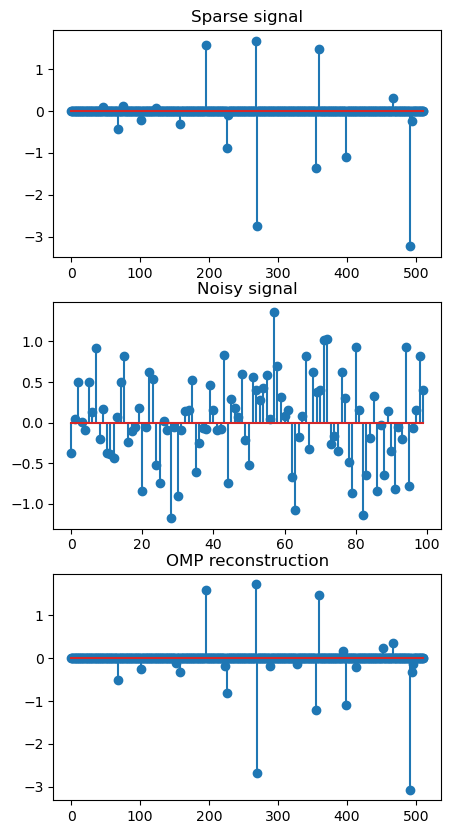

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_sparse_coded_signal
from sklearn.linear_model import OrthogonalMatchingPursuit, OrthogonalMatchingPursuitCV

n_components = 512
n_features = 100
n_nonzero_coefs = 17
n_nonzero_reconstruction_coefs = 21

y, X, w = make_sparse_coded_signal(
    n_samples=1,
    n_components=n_components,
    n_features=n_features,
    n_nonzero_coefs=n_nonzero_coefs,
    random_state=0,
)
X = X.T

x_plot = np.arange(n_components)

# distort the clean signal
y_noisy = y + 0.05 * np.random.randn(len(y))

fig, ax = plt.subplots(3, 1, figsize=(5, 10))

# plot the sparse signal
ax[0].set_title("Sparse signal")
ax[0].stem(x_plot, w)

# plot the noisy signal
ax[1].set_title("Noisy signal")
ax[1].stem(np.arange(n_features), y_noisy)

# plot the noisy reconstruction
omp = OrthogonalMatchingPursuit(n_nonzero_coefs=n_nonzero_reconstruction_coefs)
omp.fit(X, y_noisy)
ax[2].set_title("OMP reconstruction")
ax[2].stem(x_plot, omp.coef_)

# My own implementation for circulant matrices

In [2]:
class DictSparseVec:
    def __init__(self, data_dict, length=None, dtype=None):
        if dtype is None:
            self.dtype = type(list(data_dict.values())[0])
        else:
            self.dtype = dtype
        try:
            self.data_dict = {k:self.dtype(v) for k, v in data_dict.items()}
        except ValueError:
            raise ValueError(f"The dictionary values must be convertible to a single dtype ({str(dtype) if dtype is not None else "Unspecified"}).")
        if length is None:
            self.length = max(data_dict.keys()) + 1
        else:
            self.length = length

    @classmethod
    def zeros(cls, length, dtype=float):
        return cls({}, length=length, dtype=dtype)
    
    @classmethod
    def from_vec(cls, vec):
        if isinstance(vec, DictSparseVec):
            return vec
        elif not isinstance(vec, (list, tuple, np.ndarray)):
            raise ValueError("Input must be a list, tuple, or numpy array.")
        vec = np.array(vec)
        non_zero_mask = ~np.isclose(vec, 0)
        non_zero_inds = np.where(non_zero_mask)[0]
        non_zero_vals = vec[non_zero_mask]
        data_dict = {i: val for i, val in zip(non_zero_inds, non_zero_vals)}
        return cls(data_dict, length=len(vec), dtype=vec.dtype.type)
    
    def __len__(self):
        return self.length
    
    def __repr__(self):
        return f"<DictSparseVec: len={self.length}, non_zero={len(self.data_dict.keys())}, dtype={self.dtype}>"
    
    def __add__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot add a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot add vectors of different lengths.")
        all_keys = set(self.data_dict.keys()) | set(other.data_dict.keys())
        try:
            new_data_dict = {k:(self.data_dict.get(k, 0) + other.data_dict.get(k, 0)) for k in all_keys}
        except TypeError:
            raise TypeError("Cannot add vectors with incompatible dtypes.")
        return DictSparseVec(new_data_dict, length=len(self), dtype=self.dtype)
    
    def __radd__(self, other):
        return self + other
    
    def __sub__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot subtract a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot subtract vectors of different lengths.")
        all_keys = set(self.data_dict.keys()) | set(other.data_dict.keys())
        try:
            new_data_dict = {k:(self.data_dict.get(k, 0) - other.data_dict.get(k, 0)) for k in all_keys}
        except TypeError:
            raise TypeError("Cannot subtract vectors with incompatible dtypes.")
        return DictSparseVec(new_data_dict, length=len(self), dtype=self.dtype)
    
    def __rsub__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot subtract a DictSparseVec from a non-vector object.")
        return other - self
    
    def __mul__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot multiply a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot multiply vectors of different lengths.")
        common_keys = set(self.data_dict.keys()) & set(other.data_dict.keys())
        try:
            new_data_dict = {k:(self.data_dict[k] * other.data_dict[k]) for k in common_keys}
        except TypeError:
            raise TypeError("Cannot multiply vectors with incompatible dtypes.")
        return DictSparseVec(new_data_dict, length=len(self), dtype=self.dtype)
    
    def __rmul__(self, other):
        return self * other
    
    def __matmul__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot dot product a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot dot product vectors of different lengths.")
        common_keys = set(self.data_dict.keys()) & set(other.data_dict.keys())
        try:
            result = sum(self.data_dict[k] * other.data_dict[k] for k in common_keys)
        except TypeError:
            raise TypeError("Cannot dot product vectors with incompatible dtypes.")
        return result
    
    def __rmatmul__(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot dot product a non-vector object to a DictSparseVec.")
        return other @ self
    
    def convolve(self, other):
        try:
            other = DictSparseVec.from_vec(other)
        except ValueError:
            raise ValueError("Cannot convolve a DictSparseVec to a non-vector object.")
        if len(self) != len(other):
            raise ValueError("Cannot convolve vectors of different lengths.")
        new_data_dict = {}
        for kself in self.data_dict.keys():
            for kother in other.data_dict.keys():
                new_key = (kself + kother) % self.length
                if new_key not in new_data_dict:
                    new_data_dict[new_key] = 0
                new_data_dict[new_key] += self.data_dict[kself] * other.data_dict[kother]
        return DictSparseVec(new_data_dict, length=len(self), dtype=self.dtype)
    
    def roll(self, distance):
        new_data_dict = {(k + distance)%self.length:v for k, v in self.data_dict.items()}
        return DictSparseVec(new_data_dict, length=self.length, dtype=self.dtype)
    
    def sort(self):
        sorted_values = np.sort(list(self.data_dict.values()))
        sorted_dict = {k: v for k, v in enumerate(sorted_values)}
        return DictSparseVec(sorted_dict, length=self.length, dtype=self.dtype)

    def argsort(self):
        sorted_value_inds = np.argsort(list(self.data_dict.values()))
        sorted_keys = np.array(list(self.data_dict.keys()))[sorted_value_inds]
        return sorted_keys
    
    def __getitem__(self, key):
        if isinstance(key, int):
            if 0 <= key < self.length:
                return self.data_dict.get(key, 0)
            else:
                raise IndexError("Index out of bounds.")
        elif isinstance(key, slice):
            start, stop, step = key.indices(self.length)
            slice_keys = set(range(start, stop, step))
            present_keys = set(self.data_dict.keys()) & slice_keys
            return DictSparseVec({k: self.data_dict[k] for k in present_keys}, length=len(slice_keys), dtype=self.dtype)
        elif isinstance(key, (list, tuple, np.ndarray)):
            keys = np.array(key)
            if keys.ndim != 1:
                raise ValueError("Index array must be one-dimensional.")
            if not np.issubdtype(keys.dtype, np.integer):
                raise ValueError("Index array must be of integer type.")
            return DictSparseVec({np.argwhere(keys == k)[0][0]: self.data_dict[int(k)] for k in keys if self.data_dict.get(k, 0) != 0}, length=len(keys), dtype=self.dtype)
        
    def keys(self):
        return self.data_dict.keys()
    
    def values(self):
        return self.data_dict.values()
    
    def items(self):
        return self.data_dict.items()

    def clean_zeros(self):
        """Remove zero entries from the dictionary."""
        self.data_dict = {k: v for k, v in self.data_dict.items() if not np.isclose(v, 0)}
    
    def to_dense(self):
        return np.array([self.data_dict.get(i, 0) for i in range(self.length)], dtype=self.dtype)


In [3]:
from scipy.signal import fftconvolve

n = 5

# a = np.random.randn(n)
# b = np.random.randn(n)

a = np.array([1, 0, 0, 0, 0, 0, 0, 1, 0, 0])
b = np.array([1, 0, 0, 0, 1, 0, 0, 1, 0, 0])

a_s = DictSparseVec.from_vec(a)
b_s = DictSparseVec.from_vec(b)

In [4]:
a

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 0])

In [5]:
b

array([1, 0, 0, 0, 1, 0, 0, 1, 0, 0])

In [6]:
a_s.convolve(b_s).to_dense()

array([1, 1, 0, 0, 2, 0, 0, 2, 0, 0])

# Checking strategy to compute rolls

In [7]:
from scipy import sparse

N = 40
density = 0.25

v1 = sparse.random(1, N, density, format="csr").toarray()[0, :]
v2 = sparse.random(1, N, density, format="csr").toarray()[0, :]

print(v1)
print(v2)

[0.         0.22805781 0.         0.05699714 0.         0.
 0.         0.         0.         0.28967956 0.32473384 0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.59487051 0.
 0.47683176 0.20111801 0.9738725  0.         0.         0.
 0.         0.         0.         0.         0.         0.76680605
 0.         0.         0.         0.38685455]
[0.         0.         0.         0.         0.         0.
 0.40490452 0.         0.         0.         0.7070498  0.
 0.         0.62091204 0.30739039 0.         0.         0.
 0.         0.         0.         0.76584765 0.20597811 0.
 0.74383153 0.         0.97300616 0.         0.         0.
 0.         0.54080437 0.         0.         0.97021921 0.
 0.         0.         0.         0.        ]


In [8]:
def find_all_nonzero_coinciding_rolls(v1, v2):
    v1 = DictSparseVec.from_vec(v1)
    v2 = DictSparseVec.from_vec(v2)

    min_key_v1 = min(v1.keys())
    min_key_v2 = min(v2.keys())

    if min_key_v1 < min_key_v2:
        static_vector = v2
        rolling_vector = v1
    else:
        static_vector = v1
        rolling_vector = v2

    # roll_set = set()
    # for rk in rolling_vector.keys():
    #     for sk in static_vector.keys():
    #         roll = (sk - rk) % rolling_vector.length
    #         roll_set.add(roll)

    rolling_keys_arr = np.array(list(rolling_vector.keys()))
    static_keys_arr = np.array(list(static_vector.keys()))
    rolling_keys_arr = np.repeat(rolling_keys_arr, len(static_keys_arr)).reshape(-1, len(static_keys_arr))
    static_keys_arr = np.tile(static_keys_arr, (len(rolling_keys_arr), 1))
    roll_matrix = (static_keys_arr - rolling_keys_arr) % rolling_vector.length
    roll_set = set(np.unique(roll_matrix).tolist())
    
    return roll_set

def compute_dot_roll_dotproducts(v1, v2, roll_set, sort_by=None):
    """
    Sort_by: None, "increasing", "decreasing"
    """
    if sort_by not in [None, "increasing", "decreasing"]:
        raise ValueError("sort_by must be None, 'increasing', or 'decreasing'.")

    v1 = DictSparseVec.from_vec(v1)
    v2 = DictSparseVec.from_vec(v2)

    min_key_v1 = min(v1.keys())
    min_key_v2 = min(v2.keys())

    if min_key_v1 < min_key_v2:
        static_vector = v2
        rolling_vector = v1
    else:
        static_vector = v1
        rolling_vector = v2
    
    dot_products = np.zeros(len(roll_set), dtype=float)
    rolls = np.zeros(len(roll_set), dtype=int)

    for i, roll in enumerate(roll_set):
        rolled_vector = rolling_vector.roll(roll)
        dot_products[i] = static_vector @ rolled_vector
        rolls[i] = roll

    if sort_by is not None:
        arg_sorted = np.argsort(dot_products)[slice(None, None, -1 if sort_by == "decreasing" else 1)]
        dot_products = dot_products[arg_sorted]
        rolls = rolls[arg_sorted]
    
    return rolls, dot_products

In [9]:
from scipy import sparse

N = 300
density = 0.1

v1 = sparse.random(1, N, density, format="csr").toarray()[0, :]
v2 = sparse.random(1, N, density, format="csr").toarray()[0, :]

# v1 = np.array([2, 1, 0, 0, 0, 0, 0, 0, 0, 0])
# v2 = np.array([0, 1, 0, 0, 0, 0, 0, 0, 0, 2])

print(v1)
print(v2)

[0.85788546 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.15640368 0.         0.         0.         0.62705112
 0.         0.         0.         0.59062692 0.         0.
 0.         0.         0.         0.73154956 0.         0.
 0.         0.3213936  0.         0.         0.         0.
 0.15608061 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.48318602
 0.         0.41003567 0.12861985 0.         0.         0.
 0.         0.         0.         0.         0.36933682 0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.28396373 0.         0.         0.14294518
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.       

In [10]:
DictSparseVec.from_vec(v1)

<DictSparseVec: len=300, non_zero=30, dtype=<class 'numpy.float64'>>

In [11]:
DictSparseVec.from_vec(v2)

<DictSparseVec: len=300, non_zero=30, dtype=<class 'numpy.float64'>>

In [12]:
sv1 = DictSparseVec.from_vec(v1)
sv2 = DictSparseVec.from_vec(v2)

roll_set = find_all_nonzero_coinciding_rolls(sv1, sv2)
len(roll_set)

284

In [13]:
len(roll_set)

284

In [14]:
def trad_roll(v1, v2):
    N = len(v1)
    dot_products = np.zeros(N, dtype=float)
    for i in range(N):
        rolled_vector = np.roll(v2, i)
        dot_products[i] = v1 @ rolled_vector
    
    return dot_products

In [15]:
compute_dot_roll_dotproducts(sv1, sv2, roll_set, sort_by="decreasing")

(array([236, 132, 212, 299, 209, 106,  11,  52, 122,  42, 290, 262, 210,
        232,  64, 192, 188,  54, 185,  74,  38, 136,  48, 161,  16, 287,
         79, 274, 207, 100, 277, 248,   1, 273,  76, 240, 204,  20, 251,
         25,  18,  50, 206,  23, 198, 173, 115, 186, 178, 137,   2,  86,
        288, 158, 149,  85, 157,  69, 219, 183, 111, 160, 190, 264, 148,
        105, 234,  65,  70, 189, 265, 215,  13,  56, 267, 225, 202, 141,
        101,  81, 226, 110, 260,  94, 150, 187,  35, 154, 159, 131, 180,
        156, 241, 214, 211,  22, 213, 216,  67, 153,  51,  14, 107, 171,
        266,  30, 292, 152,  55, 294, 120, 169, 184, 297,  37, 233, 124,
        200, 182, 298, 130,  78,  49,  32,  89, 134,  91,  75, 181, 295,
        229, 270, 250, 162,  40, 103, 151, 246,  90, 164, 170,  34, 231,
        263, 176,  44, 126, 133,   3, 128, 268, 291, 118,  59,  60,  24,
        102,  73,  61, 238, 257, 135,  46,  47, 129,  66, 275, 109,  57,
          4, 280,  26, 208, 104,  97, 261, 220, 253

In [16]:
compute_dot_roll_dotproducts(sv1, sv2, roll_set, sort_by="decreasing")

(array([236, 132, 212, 299, 209, 106,  11,  52, 122,  42, 290, 262, 210,
        232,  64, 192, 188,  54, 185,  74,  38, 136,  48, 161,  16, 287,
         79, 274, 207, 100, 277, 248,   1, 273,  76, 240, 204,  20, 251,
         25,  18,  50, 206,  23, 198, 173, 115, 186, 178, 137,   2,  86,
        288, 158, 149,  85, 157,  69, 219, 183, 111, 160, 190, 264, 148,
        105, 234,  65,  70, 189, 265, 215,  13,  56, 267, 225, 202, 141,
        101,  81, 226, 110, 260,  94, 150, 187,  35, 154, 159, 131, 180,
        156, 241, 214, 211,  22, 213, 216,  67, 153,  51,  14, 107, 171,
        266,  30, 292, 152,  55, 294, 120, 169, 184, 297,  37, 233, 124,
        200, 182, 298, 130,  78,  49,  32,  89, 134,  91,  75, 181, 295,
        229, 270, 250, 162,  40, 103, 151, 246,  90, 164, 170,  34, 231,
        263, 176,  44, 126, 133,   3, 128, 268, 291, 118,  59,  60,  24,
        102,  73,  61, 238, 257, 135,  46,  47, 129,  66, 275, 109,  57,
          4, 280,  26, 208, 104,  97, 261, 220, 253

This is not efficient either, to check whether my assumptions on the sorting is right, create two sorted vectors and plot the dot product of the rolls

In [17]:
N = 100

v1 = np.random.rand(N)
v2 = np.random.rand(N)

array([ 0, 99,  1, 98,  2, 97,  3, 96, 95,  4, 94,  5, 93,  6, 92,  7, 91,
       90,  8, 89,  9, 88, 10, 87, 11, 86, 85, 12, 84, 13, 83, 14, 82, 15,
       81, 16, 80, 17, 79, 18, 78, 19, 77, 20, 76, 21, 75, 22, 74, 23, 73,
       24, 72, 25, 71, 26, 70, 27, 69, 28, 68, 29, 67, 30, 66, 31, 65, 64,
       32, 63, 33, 62, 34, 61, 35, 60, 36, 59, 37, 58, 38, 57, 39, 56, 55,
       40, 54, 41, 53, 52, 42, 51, 50, 43, 48, 49, 47, 44, 45, 46])

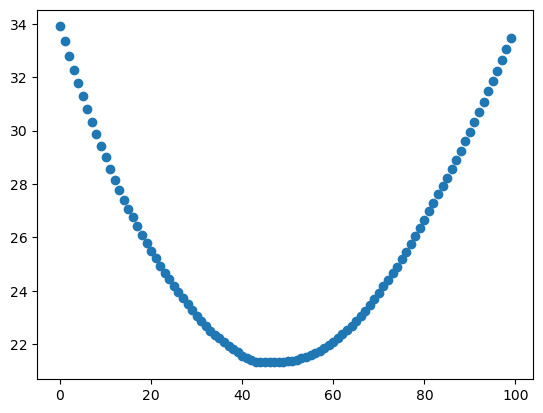

In [18]:
def bruteforce_get_sorted_dot_products(v1, v2):
    v1 = np.sort(v1)[::-1]
    v2 = np.sort(v2)[::-1]
    dot_products = np.zeros(N, dtype=float)
    for i in range(N):
        dot_products[i] = v1 @ np.roll(v2, i)
    return dot_products

dot_products = bruteforce_get_sorted_dot_products(v1, v2)
plt.plot(dot_products, "o")
np.argsort(dot_products)[::-1]

In [19]:
np.sort(v1)

array([0.01342921, 0.02290072, 0.03927977, 0.06582944, 0.07500116,
       0.07940065, 0.08441441, 0.08655532, 0.10688937, 0.11538431,
       0.11641679, 0.11994684, 0.1256327 , 0.15119521, 0.15911111,
       0.16410082, 0.16577221, 0.16951117, 0.18384292, 0.18454765,
       0.19310894, 0.21646736, 0.22121937, 0.22612849, 0.2366333 ,
       0.24796541, 0.25765479, 0.27248298, 0.28118985, 0.28855451,
       0.29232909, 0.30038998, 0.3026137 , 0.33167326, 0.34889758,
       0.35532036, 0.36184253, 0.36865822, 0.38109966, 0.38630429,
       0.38819008, 0.38908247, 0.39211069, 0.39454147, 0.40694024,
       0.41577671, 0.41700158, 0.42279818, 0.43851744, 0.44145417,
       0.44153325, 0.46545237, 0.46731695, 0.47150493, 0.47979835,
       0.49961095, 0.5182261 , 0.52167395, 0.54821892, 0.56085164,
       0.58643219, 0.58700891, 0.61739856, 0.61857762, 0.62124598,
       0.62822285, 0.63262946, 0.65450332, 0.65569124, 0.65771893,
       0.66232804, 0.6637833 , 0.67273755, 0.67880206, 0.68225

# Using correlations to find max shifts

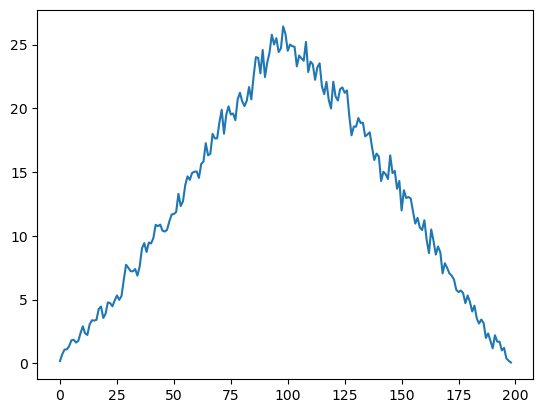

In [20]:
import matplotlib.pyplot as plt
from scipy import signal

corr = signal.correlate(v1, v2, mode="full")

x = np.arange(len(corr))
plt.plot(x, corr, "-")

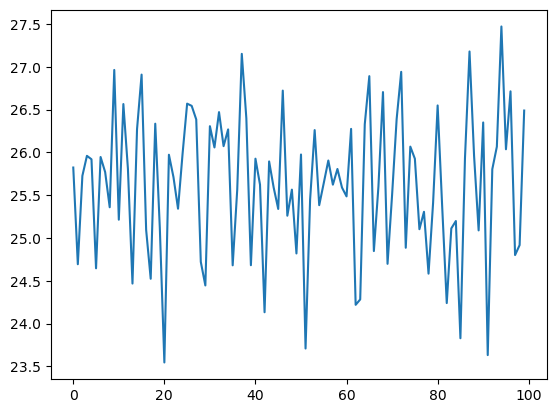

In [21]:
dot_products = trad_roll(v1, v2)

x = np.arange(len(v1))
plt.plot(x, dot_products, "-")

y2 is 1.5151515151515156 behind y1


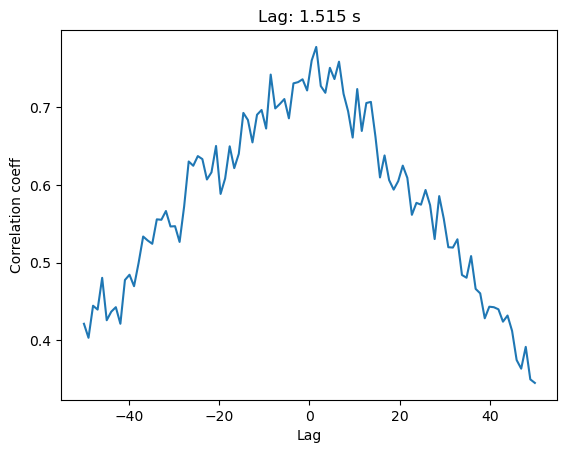

In [22]:
def lag_finder(y1, y2, sr):
    n = len(y1)

    corr = signal.correlate(y2, y1, mode='same') / np.sqrt(signal.correlate(y1, y1, mode='same')[int(n/2)] * signal.correlate(y2, y2, mode='same')[int(n/2)])

    delay_arr = np.linspace(-0.5*n/sr, 0.5*n/sr, n)
    delay = delay_arr[np.argmax(corr)]
    print('y2 is ' + str(delay) + ' behind y1')

    plt.figure()
    plt.plot(delay_arr, corr)
    plt.title('Lag: ' + str(np.round(delay, 3)) + ' s')
    plt.xlabel('Lag')
    plt.ylabel('Correlation coeff')
    plt.show()

lag_finder(v1, v2, 1)

In [23]:
import numpy as np
from scipy.signal import correlate

def find_max_circular_correlation(static_vec, rolling_vec):
    """
    Find the maximum dot product between static_vec and all circular shifts of rolling_vec.
    
    Parameters:
        static_vec: The vector that remains fixed
        rolling_vec: The vector to be circularly shifted
        
    Returns:
        max_dot_product: Maximum dot product value
        optimal_shift: Shift that produces the maximum dot product
    """
    n = len(static_vec)
    
    # Perform the full correlation
    corr_result = correlate(static_vec, rolling_vec, mode="full")
    
    # Extract the circular correlation values
    circular_corr = np.zeros(n)
    for i in range(n):
        # For each shift, combine the appropriate parts of the linear correlation
        circular_corr[i] = corr_result[n-1+i]
        if i > 0:
            circular_corr[i] += corr_result[i-1]
    
    # Find the maximum value and its index
    max_dot_product = np.max(circular_corr)
    optimal_shift = np.argmax(circular_corr)
    
    return max_dot_product, optimal_shift

In [24]:
v1 = np.array([1, 2, 3, 4])
v2 = np.array([4, 1, 2, 3])
max_dot_product, optimal_shift = find_max_circular_correlation(v1, v2)
print("Max dot product:", max_dot_product)
print("Optimal shift:", optimal_shift)

Max dot product: 30.0
Optimal shift: 3


# Assuming order of first column rolls is maintained

In [25]:
from scipy.signal import correlate

def circular_correlation(static_vec, rolling_vec):
    """
    Find the maximum dot product between static_vec and all circular shifts of rolling_vec.
    
    Parameters:
        static_vec: The vector that remains fixed
        rolling_vec: The vector to be circularly shifted
        
    Returns:
        max_dot_product: Maximum dot product value
        optimal_shift: Shift that produces the maximum dot product
    """
    n = len(static_vec)
    
    # Perform the full correlation
    corr_result = correlate(static_vec, rolling_vec, mode="full")
    
    # Extract the circular correlation values
    circular_corr = np.zeros(n)
    for i in range(n):
        # For each shift, combine the appropriate parts of the linear correlation
        circular_corr[i] = corr_result[n-1+i]
        if i > 0:
            circular_corr[i] += corr_result[i-1]
    
    # Find the maximum value and its index
    return circular_corr

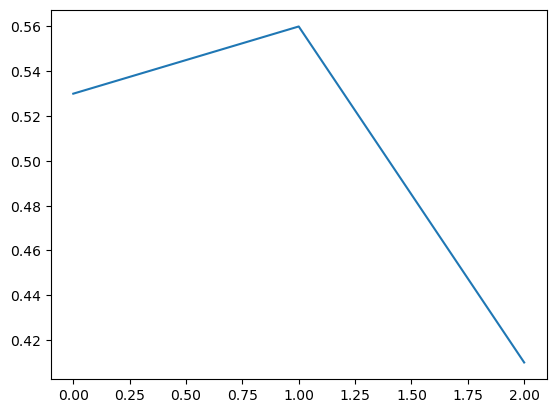

In [26]:
import matplotlib.pyplot as plt
import numpy as np

v1 = np.array([0.2, 0.3, 0.5])
# v1 = np.array([0, 0.3, 0.5])
v2 = np.array([0.2, 0.8, 0.5])
ccorr = circular_correlation(v1, v2)

plt.plot(np.arange(len(ccorr)), ccorr)

In [27]:
trad_roll(v1, v2)

array([0.53, 0.56, 0.41])

In [28]:
v1@v2

0.53

In [284]:
import scipy.sparse as sparse

N = 5
row_density = 0.6
x_density = 0.4

c = sparse.random(1, N, row_density, format="csr").toarray()[0, :]
# c = np.array([0, 0.2, 0, 0.3, 0.5])
c = c / np.linalg.norm(c)
non_zero = np.where(c != 0)[0]

phi = np.zeros((len(non_zero), N))
for i, nz in enumerate(non_zero):
    phi[i, :] = np.roll(c, -nz)

print(phi)

x = sparse.random(1, N, x_density, format="csr", dtype=bool).toarray()[0, :].astype(int)
# x = np.array([1, 1, 0, 0, 0])
r = phi @ x

dot_products = np.zeros(N, dtype=float)
for i in range(N):
    dot_products[i] = r @ phi[:, i]

print(dot_products)

[[0.68225044 0.30549776 0.66423298 0.         0.        ]
 [0.30549776 0.66423298 0.         0.         0.68225044]
 [0.66423298 0.         0.         0.68225044 0.30549776]]
[0.86452091 0.53453433 0.20292168 0.46546567 0.66159923]


In [285]:
corr = circular_correlation(r, phi[:, 0])
print(f"Max corr with roll {np.argmax(corr)}")

Max corr with roll 2


In [286]:
corr

array([0.86452091, 0.86452091, 1.        ])

# Dot products of probability vectors

In [413]:
N = 100
row_density = 0.2

v1 = sparse.random(1, N, row_density, format="csr").toarray()[0, :]
v1 = v1 / np.sum(v1)
v2 = sparse.random(1, N, row_density, format="csr").toarray()[0, :]
v2 = v2 / np.sum(v2)

print(v1)
print(v2)

[0.         0.         0.         0.         0.         0.
 0.         0.         0.04441195 0.         0.         0.
 0.         0.         0.         0.         0.07829304 0.
 0.         0.         0.03648376 0.09201538 0.         0.00146758
 0.         0.         0.07226793 0.03373274 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.02590187 0.         0.         0.         0.
 0.         0.         0.11024864 0.         0.         0.0403759
 0.         0.05198834 0.         0.         0.         0.
 0.         0.         0.         0.         0.07762989 0.
 0.         0.         0.0142071  0.08702929 0.         0.02272749
 0.         0.         0.00075795 0.         0.00016499 0.
 0.01355748 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.08719053 0.         0.10954816 0.         0.         0.
 0.         0.         0.        

In [414]:
print(tr := trad_roll(v1, v2))
print(np.argmax(tr))
print(v1)
print(np.roll(v2, np.argmax(tr)))

[0.01271336 0.01217057 0.00944138 0.01186034 0.00253934 0.0109157
 0.00339593 0.01897886 0.01577143 0.00377626 0.01399515 0.01367781
 0.02094651 0.01188861 0.00911732 0.00465993 0.00739031 0.00597534
 0.00275607 0.00504149 0.01257045 0.00483693 0.00696101 0.00847632
 0.0142525  0.01909138 0.00366204 0.01260831 0.00480516 0.01998435
 0.01180657 0.01739733 0.00931528 0.01360493 0.01609341 0.01375005
 0.00575219 0.01215827 0.00322872 0.00901234 0.00582731 0.01387761
 0.00683817 0.00650055 0.00536686 0.00539934 0.00624604 0.00322921
 0.01265044 0.00758662 0.01787266 0.0148205  0.00595909 0.01149434
 0.01425947 0.00721841 0.0051126  0.01148003 0.01311495 0.01560411
 0.01390233 0.01451775 0.01512096 0.01382547 0.01096505 0.00318412
 0.00630918 0.00478785 0.00992011 0.01370834 0.00430733 0.01088786
 0.00632016 0.01367834 0.00570658 0.006923   0.00546972 0.01514708
 0.00502386 0.0194934  0.00700911 0.01730442 0.0073747  0.01614911
 0.00804304 0.00506022 0.0119867  0.01239967 0.0044377  0.00627

In [415]:
roll = 2
print(rv1 := np.roll(v1, roll))
print(rv2 := np.roll(v2, 0))
print(rv1 @ rv2)

[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.04441195 0.
 0.         0.         0.         0.         0.         0.
 0.07829304 0.         0.         0.         0.03648376 0.09201538
 0.         0.00146758 0.         0.         0.07226793 0.03373274
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.02590187 0.         0.
 0.         0.         0.         0.         0.11024864 0.
 0.         0.0403759  0.         0.05198834 0.         0.
 0.         0.         0.         0.         0.         0.
 0.07762989 0.         0.         0.         0.0142071  0.08702929
 0.         0.02272749 0.         0.         0.00075795 0.
 0.00016499 0.         0.01355748 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.08719053 0.         0.10954816 0.
 0.         0.         0.       

In [416]:
roll = 2
print(v1)
print(np.roll(v2, roll))
print(v1 @ np.roll(v2, roll))

[0.         0.         0.         0.         0.         0.
 0.         0.         0.04441195 0.         0.         0.
 0.         0.         0.         0.         0.07829304 0.
 0.         0.         0.03648376 0.09201538 0.         0.00146758
 0.         0.         0.07226793 0.03373274 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.02590187 0.         0.         0.         0.
 0.         0.         0.11024864 0.         0.         0.0403759
 0.         0.05198834 0.         0.         0.         0.
 0.         0.         0.         0.         0.07762989 0.
 0.         0.         0.0142071  0.08702929 0.         0.02272749
 0.         0.         0.00075795 0.         0.00016499 0.
 0.01355748 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.08719053 0.         0.10954816 0.         0.         0.
 0.         0.         0.        

99


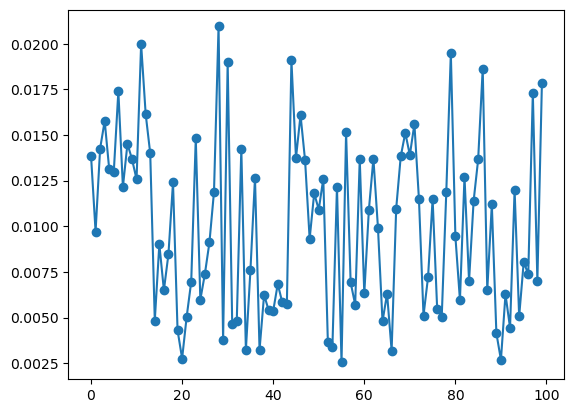

In [417]:
import matplotlib.pyplot as plt

max_iter = N

static_vector = v1 if np.max(v1) > np.max(v2) else v2
rolling_vector = v2 if np.max(v1) > np.max(v2) else v1

candidate_rolls = []
static_max_el = np.argmax(static_vector)
rolling_argsort = np.argsort(rolling_vector)[::-1]
max_roll_index = None
for i, v2i in enumerate(rolling_argsort):
    last_roll = candidate_rolls[-1] if candidate_rolls else 0
    this_roll_index = (static_max_el - v2i) % N
    this_roll = static_vector @ np.roll(rolling_vector, this_roll_index)
    if this_roll > last_roll:
        max_roll_index = i
    candidate_rolls.append(this_roll)
    last_roll = this_roll

print(max_roll_index)
plt.plot(np.arange(i+1), candidate_rolls, "o-")

In [418]:
1/25/0.2

0.19999999999999998

In [419]:
max_roll_index

99

In [420]:
np.argmax(candidate_rolls)

28

In [421]:
1/N

0.01

In [422]:
print(v1 @ np.roll(v2, 0))
print(v1 @ np.roll(v2, 2))
print(v1 @ np.roll(v2, 3))

0.012713355706672133
0.009441377370855182
0.011860335974164193
